<a href="https://colab.research.google.com/github/lcy412/udl_pratical/blob/main/Playing_with_Uncertainties.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# When do we benefit from a probabilistic framework?
In this practical we'll play with a toy problem that demonstrates when we benefit from probabilistic approaches. We'll see that we can be more principled and get better results than our standard approach.

## 0. Prologue 🔰
Whenever we do ML we usually assume that our error is as simple as can be, that being normally distributed. However, often this isn't the case - for example:
1. When measuring how high someone jumps there'll be a bigger error if they jump higher.
2. Sometimes errors can be [bimodal](https://en.wikipedia.org/wiki/Multimodal_distribution). If we're classifying traffic signs we might have high accuracy during the day and low during the night.
This is known as [heteroscedastic uncertainty](https://en.wikipedia.org/wiki/Homoscedasticity_and_heteroscedasticity), where our error depends on our input.

For starters, let's try and deal with this in an artificial setting. Often bigger inputs have larger errors, like in the height example. We'll see what happens when we naively model a function like
$$
f(x)=\cos(x)+\frac{x^2}{5}+xϵ\\
ϵ\sim\mathbb{N}(0,\sigma^2)
$$
where $\sigma^2$ is some innate variance.

❔  
**Q0:** what do you expect to happen when we fit something to this using a regular mean squared error?

**A:** MSE treats all observations equally, even though some observations have much higher noise. As a result, those data with high-noise have more influence on the training process.

❔  
**Q1:** is this aleatoric or epistemic uncertainty?  



**A:** This is aleatoric uncertainty because it comes from the inherent randomness in the data-generating process, and the noise variance depends on the input \(x\). The uncertainty exsists even with more data.



##### Here's some boilerplate code that'll help us later on.

In [ ]:
import numpy as np

def gt_func(x):
  return np.cos(x)+x**2/5

def gen_data(n_points, sigma=.1):
  x = np.linspace(-4, 4, n_points)
  y = gt_func(x)+x*sigma*np.random.randn(n_points)

  x = torch.tensor(x).float().unsqueeze(-1)
  y = torch.tensor(y).float()

  return x, y

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def train_model(x, y, model, loss_fn, lr: float=1e-3, n_epochs: int=300, bs: int=25):
  optimiser = torch.optim.Adam(model.parameters(), lr=lr)
  dloader = DataLoader(list(zip(x, y)), shuffle=True, batch_size=bs)

  for epoch in range(n_epochs):
    train_loss = 0
    for batch_x, batch_y in dloader:
      optimiser.zero_grad()

      output = model(batch_x)
      loss = loss_fn(output, batch_y.unsqueeze(-1))

      loss.backward()
      optimiser.step()

      train_loss += loss.item() * len(batch_x)

    train_loss /= len(x)

    if epoch % 20  == 0:
      print(f'Epoch: {epoch+1}/{n_epochs}, loss: {train_loss:.4f}')

  return model

In [ ]:
import matplotlib.pyplot as plt

def plot_preds(model, x, y):
  preds = model(x).detach().numpy()

  x = x.numpy()
  plt.scatter(x, y, label='data')
  if preds.shape[1] == 1:
    plt.scatter(x, preds, label='predictions', c='r')
  else:
    a = preds[:, 0]
    b = np.exp(.5 * preds[:, 1])
    plt.errorbar(x, a, yerr=b, label='predictions', marker='o',
                 linestyle='None', c='r')

  x = np.linspace(-4, 4)
  plt.plot(x, gt_func(x), label='ground truth')

  plt.xlabel('x')
  plt.ylabel('y')
  plt.legend()

## 1. Back to basics 🐣
For starters let's try solving the problem as we usually, would, assuming the errors are normally distributed. This naturally leads us to us a mean squared error (MSE) loss with some given constant standard deviation $\tilde{\sigma}$.

❔  
**Q2** generate 25 training points from the heteroscedastic model and fit an MLP to it.
1. What's the training error?
2. When evaluating on 200 test points what's the test error? Explain the difference.
3. What happens when the number of training points is increased? Would this always happen?
4. [Optional] What's the theoretical best test error, assuming infinite data?
5. [Optional] Estimate $\tilde{\sigma}$. How does it compare to the real $\sigma$?

❗  
**Attention** when calculating final train/test errors make sure your loss function's inputs have the same shape. If your model outputs are a column vector while the targets are a row vector it won't calculate the loss properly. Usually you need to `unsqueeze` your ground truth labels or `squeeze` your model's output.

In [ ]:
class MLP(nn.Module):
  def __init__(self, n_inputs: int, n_outputs: int):
    super(MLP, self).__init__()

    self.layers = nn.Sequential(
        nn.Linear(n_inputs, 512),
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, n_outputs)
    )

  def forward(self, x):
    return self.layers(x)

In [ ]:
train_x, train_y = gen_data(25)

In [ ]:
model = MLP(1,1)
model = train_model(train_x, train_y, model, loss_fn=nn.MSELoss())

Epoch: 1/300, loss: 1.2590
Epoch: 21/300, loss: 0.2098
Epoch: 41/300, loss: 0.1298
Epoch: 61/300, loss: 0.0549
Epoch: 81/300, loss: 0.0318
Epoch: 101/300, loss: 0.0285
Epoch: 121/300, loss: 0.0276
Epoch: 141/300, loss: 0.0268
Epoch: 161/300, loss: 0.0259
Epoch: 181/300, loss: 0.0249
Epoch: 201/300, loss: 0.0242
Epoch: 221/300, loss: 0.0226
Epoch: 241/300, loss: 0.0214
Epoch: 261/300, loss: 0.0198
Epoch: 281/300, loss: 0.0189


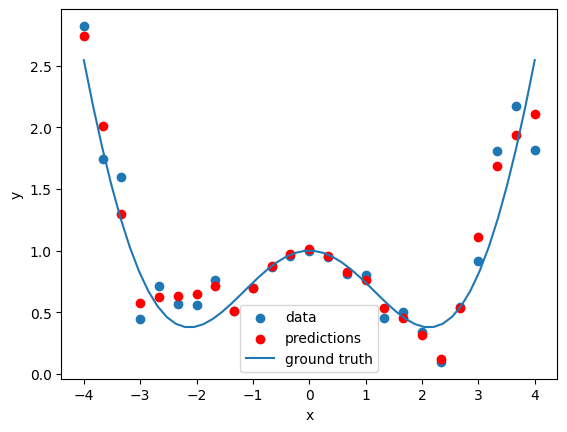

In [ ]:
plot_preds(model, train_x, train_y)

In [ ]:
# additional code goes here

model.eval()

with torch.no_grad():
    train_pred = model(train_x)
    train_error = nn.MSELoss()(train_pred.squeeze(), train_y.squeeze())

print("Training error:", train_error.item())


#Generate 200 test points and calculate test error
test_x, test_y = gen_data(200)

with torch.no_grad():
    test_pred = model(test_x)
    test_error = nn.MSELoss()(test_pred.squeeze(), test_y.squeeze())

print("Test error:", test_error.item())


#Increase the number of training points
train_x_large, train_y_large = gen_data(200)

model_large = MLP(1, 1)
model_large = train_model(
    train_x_large,
    train_y_large,
    model_large,
    loss_fn=nn.MSELoss()
)

model_large.eval()

with torch.no_grad():
    test_pred_large = model_large(test_x)
    test_error_large = nn.MSELoss()(
        test_pred_large.squeeze(),
        test_y.squeeze()
    )

print("Test error with 200 training points:", test_error_large.item())


with torch.no_grad():
    predictions = model_large(test_x).squeeze()
    residuals = test_y.squeeze() - predictions

    sigma_tilde = torch.sqrt(torch.mean(residuals ** 2))

print("Estimated sigma:", sigma_tilde.item())

Training error: 0.016895558685064316
Test error: 0.08402583748102188
Epoch: 1/300, loss: 0.4294
Epoch: 21/300, loss: 0.0919
Epoch: 41/300, loss: 0.0623
Epoch: 61/300, loss: 0.0884
Epoch: 81/300, loss: 0.0661
Epoch: 101/300, loss: 0.0586
Epoch: 121/300, loss: 0.0590
Epoch: 141/300, loss: 0.0591
Epoch: 161/300, loss: 0.0558
Epoch: 181/300, loss: 0.0594
Epoch: 201/300, loss: 0.0571
Epoch: 221/300, loss: 0.0657
Epoch: 241/300, loss: 0.0552
Epoch: 261/300, loss: 0.0536
Epoch: 281/300, loss: 0.0603
Test error with 200 training points: 0.06360401958227158
Estimated sigma: 0.25219836831092834


**A:**

1. The training error is 0.01690 using MSE.

2. The test error is 0.08402, higher than the training error. This suggests that the model may be overfitting the small training dataset of 25 points. The model fits the training data well but struggles to generalise to unseen data.

3. When the number of training points increases from 25 to 200, the test error decreases from 0.08402 to 0.063604. This suggests that more training data can improve generalisation by reducing overfitting.

4. With infinite training data, the optimal MSE predictor converges to the conditional mean $f(x)=\mathbb E[y\mid x]$. However, the random noise cannot be predicted. Therefore, the theoretical minimum test MSE is $\mathbb E_x[\sigma^2(x)]$.

5. The estimated $$\tilde{\sigma}=\approx 0.2522$$, the gt is 0.1

## 2. Principled Probability 🧠
❔  
**Q3:** MSE is motivated through the negative log likelihood when doing OLS. Review this derivation _(if you never explicitly did this, [look here at chapter 11, pages 371-373](https://probml.github.io/pml-book/book1.html))_. List out your assumptions - do they hold for this problem?

**A:**

Assuming that the errors are independent and normally distributed with zero mean and constant variance $\tilde{\sigma}^2$, we have

$$
y_i \mid x_i \sim \mathcal{N}(f(x_i), \tilde{\sigma}^2)
$$

The negative log-likelihood is

$$
-\log L = \frac{N}{2}\log(2\pi\tilde{\sigma}^2) + \frac{1}{2\tilde{\sigma}^2}\sum_{i=1}^{N}(y_i-\hat{f}(x_i))^2
$$

Since $\tilde{\sigma}$ is constant, minimising the negative log-likelihood with respect to the model parameters is equivalent to minimising MSE.

The main assumptions are:

1. **Gaussian errors:** The errors follow a normal distribution.
2. **Independent errors:** The errors are independent across observations.
3. **Homoscedasticity:** The errors have constant variance.

In our problem, the first two assumptions hold. However, the constant variance assumption is violated because

$$
\operatorname{Var}(y \mid x) = (0.1x)^2 = 0.01x^2
$$

which depends on $x$. Therefore, the data is heteroscedastic, and the constant-variance Gaussian assumption does not hold.

❔  
**Q4:** for simplicitly let's continue assuming our data is normally distributed. How can you model heteroscedastic noise? What would you need to change in the previous derivation? _Note - we typically don't a priori know how noisy our data is, e.g. in OLS we don't assume we know the data's variance_.

**A:**

To model heteroscedastic noise, we allow the variance to depend on the input $x$.

We assume:

$$
y_i \mid x_i \sim \mathcal{N}(\mu(x_i), \sigma^2(x_i))
$$

where both the mean $\mu(x_i)$ and variance $\sigma^2(x_i)$ are learned by the model.





❔  
**Q5:** using that new assumption you should be able to follow the derivation in **Q3** to get a <ins>new, principled loss function</ins> that incorporates this noise. What is it?

**A:**


Assuming heteroscedastic Gaussian noise, we have:

$$
y_i \mid x_i \sim \mathcal{N}(\mu(x_i), \sigma^2(x_i))
$$

The probability density function is:

$$
p(y_i \mid x_i) = \frac{1}{\sqrt{2\pi\sigma^2(x_i)}}\exp\left(-\frac{(y_i-\mu(x_i))^2}{2\sigma^2(x_i)}\right)
$$

Assuming independent observations, the likelihood is:

$$
L = \prod_{i=1}^{N}p(y_i \mid x_i)
$$

Taking the negative logarithm gives:

$$
-\log L = \frac{1}{2}\sum_{i=1}^{N}\left[\log(2\pi\sigma^2(x_i))+\frac{(y_i-\mu(x_i))^2}{\sigma^2(x_i)}\right]
$$

Dropping the constant term and averaging over all samples, we obtain the new loss function:

$$
{\mathcal{L} = \frac{1}{2N}\sum_{i=1}^{N}\left[\log\sigma^2(x_i)+\frac{(y_i-\mu(x_i))^2}{\sigma^2(x_i)}\right]}
$$



❔  
**Q6:** let's test this in practice! Implement the loss function, change your model however you see fit, and repeat **Q2**.

🧩  
_Hint:_ if you need to predict a positive parameter usually its easier to predict a real parameter $s$ and then make it positive by mapping $s→\exp(s)$.

In [13]:
def loss_fn(output, target):
  mu = output[:, 0:1]
  log_var = output[:, 1:2]

  loss = 0.5 * (
      log_var + (target - mu)**2 * torch.exp(-log_var)
  )

  return loss.mean()




In [17]:
# Generate 25 training points
train_x, train_y = gen_data(25)

model = MLP(1, 2)
model = train_model(train_x, train_y, model, loss_fn=loss_fn)

model.eval()

with torch.no_grad():
    train_pred = model(train_x)[:, 0]
    train_error = nn.MSELoss()(train_pred, train_y)

print("Training error:", train_error.item())


# Generate 200 test points
test_x, test_y = gen_data(200)

with torch.no_grad():
    test_pred = model(test_x)[:, 0]
    test_error = nn.MSELoss()(test_pred, test_y)

print("Test error:", test_error.item())


# Increase the number of training points
train_x_large, train_y_large = gen_data(200)

model_large = MLP(1, 2)
model_large = train_model(
    train_x_large,
    train_y_large,
    model_large,
    loss_fn=loss_fn
)

model_large.eval()

with torch.no_grad():
    test_pred_large = model_large(test_x)[:, 0]
    test_error_large = nn.MSELoss()(test_pred_large, test_y)

print("Test error with 200 training points:", test_error_large.item())

Epoch: 1/300, loss: 0.6752
Epoch: 21/300, loss: -0.2069
Epoch: 41/300, loss: -1.1251
Epoch: 61/300, loss: -1.3071
Epoch: 81/300, loss: -1.5883
Epoch: 101/300, loss: -1.1359
Epoch: 121/300, loss: -1.1161
Epoch: 141/300, loss: -1.4278
Epoch: 161/300, loss: -1.7118
Epoch: 181/300, loss: -1.7158
Epoch: 201/300, loss: -1.7427
Epoch: 221/300, loss: -1.9975
Epoch: 241/300, loss: -1.4616
Epoch: 261/300, loss: -1.7529
Epoch: 281/300, loss: -1.7588
Training error: 0.13431233167648315
Test error: 0.09655123949050903
Epoch: 1/300, loss: 0.0915
Epoch: 21/300, loss: -0.9840
Epoch: 41/300, loss: -1.2125
Epoch: 61/300, loss: -1.1942
Epoch: 81/300, loss: -1.1989
Epoch: 101/300, loss: -1.2547
Epoch: 121/300, loss: -1.2625
Epoch: 141/300, loss: -1.3195
Epoch: 161/300, loss: -1.1642
Epoch: 181/300, loss: -1.3657
Epoch: 201/300, loss: -1.3435
Epoch: 221/300, loss: -1.3451
Epoch: 241/300, loss: -1.3816
Epoch: 261/300, loss: -1.3418
Epoch: 281/300, loss: -1.3751
Test error with 200 training points: 0.0561829

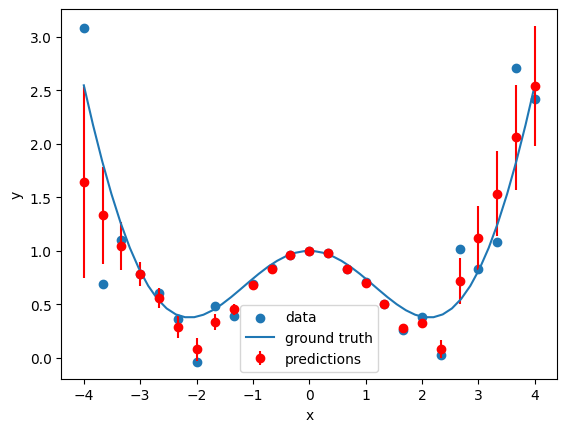

In [18]:
plot_preds(model, train_x, train_y)

**A:** The model generally captures the underlying function, as most predictions are close to the ground truth. The predicted uncertainty appears larger near the boundaries and smaller around the centre, which is consistent with the heteroscedastic noise in the data.

With 25 training points, the training MSE is 0.1343 and the test MSE is 0.0966. When the number of training points increases to 200, the test MSE decreases to 0.0562, approaching the theoretical minimum of approximately 0.0533.


❔  
**Q7:** you may have gotten a negative loss at times, which seems quite odd! We were principled, derived everything based on seemingly sound assumptions, checked our code, what went wrong? If we're calculating $-\log(p)$ and $p$ is a probability, so $0\le p\le 1$, this should always be positive. What's wrong here?

**A:** We omitted the constant term in the Gaussian NLL because it does not affect optimisation. However, even if we include this constant, the NLL can still be negative because probability densities can exceed 1.

❔  
**Q8:** if all went well this model should have gotten a lower test MSE than the previous one. _This is awfully peculiar!_ We trained it on a different loss yet it still performed better than an almost identical model trained to minimise MSE directly. Why did this happen? When would we expect this not to occur?

**A:** The Gaussian NLL loss accounts for heteroscedastic noise by assigning lower weights to noisier observations and higher weights to more reliable ones.

 - If the noise is homoscedastic, MSE is already appropriate.
 - With infinite training data and a sufficiently expressive model.

❔  
**Q9:** are the regular and "uncertainty-aware" models equally powerful? Is there anything that could give one an edge over the other?

**A:** No. The regular one only predicts the mean, while the uncertainty-aware one predicts both the mean and the input-dependent variance.

The uncertainty-aware model has additional output and can represent heteroscedastic noise, giving it an advantage when modelling uncertainty.

However, this also makes the optimisation more complex, so it does not necessarily achieve better mean predictions, especially with limited training data.

❔  
**Q10:** [Optional] how could we incorporate the other kind of uncertainty into this model?

**A:** We could train multiple uncertainty-aware models with different random initialisations and estimate epistemic uncertainty from the variance of their mean predictions.


# 3. Epilogue 🛌
So that was a cool problem and all, but when is this actually relevant? One interesting use case is for depth-perception in autonomous driving. Here given a picture one needs to predict the distance to each pixel. The noise is extremely heteroscedastic so incorporating uncertainty is beneficial. Here are examples from [this paper](https://arxiv.org/pdf/1703.04977.pdf) - left to right are the input image, ground truth, depth prediction, and aleatoric uncertainty (AKA predicted $\sigma$). In the bottom row one can see there's high uncertainty about the man in the bathroom. In all the pictures the uncertainty generally increases with distance.
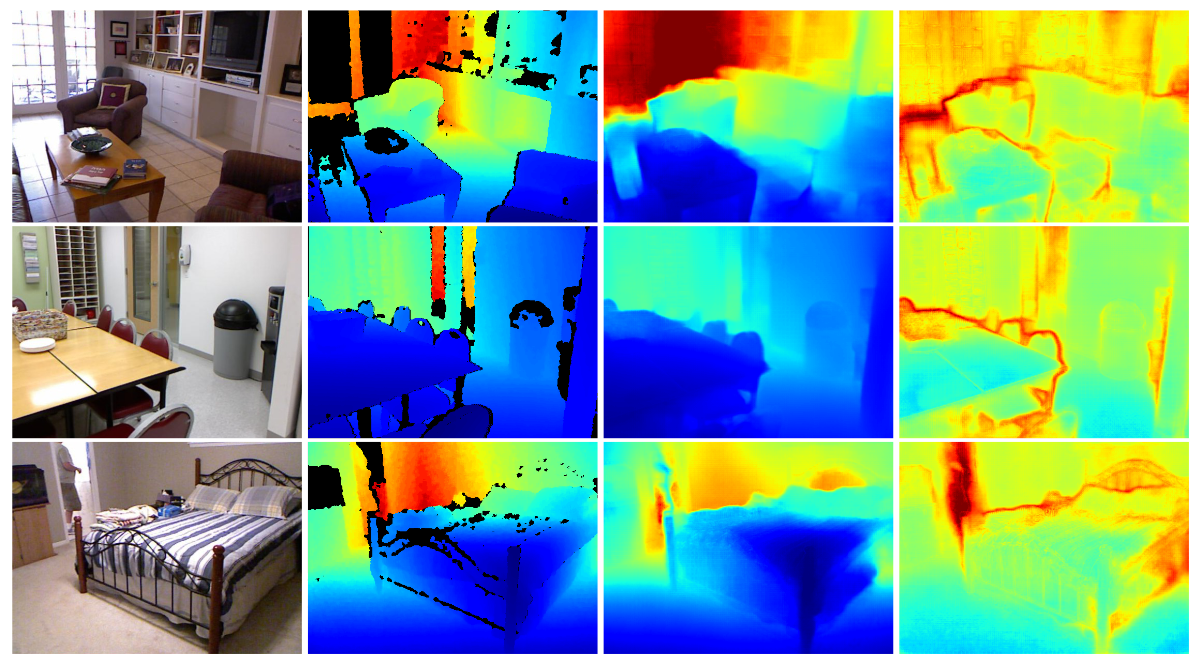